# 03 — Explainability of the p50 demand forecast with SHAP

This notebook explains **one product/branch forecast** from the champion quantile
model, using SHAP values for the p50 (median) model. SHAP is optional: if it is not
installed, the notebook prints an install hint and falls back to the native XGBoost
gain importance, so the audit still runs offline.

**Inputs**

- `artifacts/models/xgboost_global.joblib` — the quantile bundle and its feature metadata.
- `artifacts/models/registry.json` — model version and dataset fingerprint.
- `data/processed/demand_daily.csv` — loaded through `src.data_contracts.load_csv`.

**Feature construction.** Features are rebuilt with
`src.pipelines.features.build_supervised` on the **full panel**, not on a single series:
the model was trained with categorical encoders fitted on the full dataset, and
re-fitting encoders on one product would silently change `product_code` /
`demand_pattern_code` and invalidate the explanation. The holdout rows for the chosen
series are then selected from the global validation frame.

**Optional dependency**

```bash
pip install shap   # or .venv/bin/pip install shap
```

`matplotlib` is guarded too; without it the notebook prints tables instead of charts.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import warnings

warnings.filterwarnings("ignore", message=".*joblib will operate in serial mode.*")

import joblib
import numpy as np
import pandas as pd

REPO_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "src" / "pipelines").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Cannot locate the repository root. Start Jupyter from the repository root "
        "or from notebooks/ so that src/ is visible."
    )
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_contracts import load_csv  # noqa: E402
from src.pipelines.features import FEATURES, build_supervised  # noqa: E402

DATA_PATH = REPO_ROOT / "data" / "processed" / "demand_daily.csv"
MODEL_PATH = REPO_ROOT / "artifacts" / "models" / "xgboost_global.joblib"
REGISTRY_PATH = REPO_ROOT / "artifacts" / "models" / "registry.json"

missing = [path for path in (DATA_PATH, MODEL_PATH, REGISTRY_PATH) if not path.exists()]
if missing:
    relative = ", ".join(str(path.relative_to(REPO_ROOT)) for path in missing)
    raise FileNotFoundError(
        f"Missing inputs: {relative}. Run `make data` and `make train` first."
    )
print(f"Data:    {DATA_PATH.relative_to(REPO_ROOT)}")
print(f"Model:   {MODEL_PATH.relative_to(REPO_ROOT)}")

Data:    data/processed/demand_daily.csv
Model:   artifacts/models/xgboost_global.joblib


In [2]:
try:
    import matplotlib.pyplot as plt

    MATPLOTLIB_AVAILABLE = True
except ImportError:
    plt = None
    MATPLOTLIB_AVAILABLE = False

MATPLOTLIB_HINT = (
    "matplotlib is not installed, so charts are skipped and tables are printed "
    "instead. Install it with `pip install matplotlib` "
    "(or `.venv/bin/pip install matplotlib`) and re-run this cell."
)

COLOR_MAIN = "#2f6f8f"


def plots_available() -> bool:
    # True when matplotlib can render; otherwise print an actionable hint.
    if not MATPLOTLIB_AVAILABLE:
        print(MATPLOTLIB_HINT)
    return MATPLOTLIB_AVAILABLE

In [3]:
try:
    import shap

    SHAP_AVAILABLE = True
except ImportError:
    shap = None
    SHAP_AVAILABLE = False

SHAP_HINT = (
    "shap is not installed, so this notebook falls back to the native XGBoost gain "
    "importance. Install it with `pip install shap` "
    "(or `.venv/bin/pip install shap`) and re-run the notebook."
)

if SHAP_AVAILABLE:
    print(f"shap {shap.__version__} is available.")
else:
    print(SHAP_HINT)

shap 0.54.1 is available.


## 1. Load the champion and align the feature contract

The bundle stores `{"models": {"p10", "p50", "p90"}, "meta": ...}`; `meta["features"]`
must match `src.pipelines.features.FEATURES` exactly. If it does not, the artifact and
the serving code are out of sync and the explanation would be meaningless.

In [4]:
bundle = joblib.load(MODEL_PATH)
registry = json.loads(REGISTRY_PATH.read_text(encoding="utf-8"))

models = bundle["models"]
meta = bundle["meta"]
p50 = models["p50"]
features = list(meta["features"])

if features != list(FEATURES):
    raise ValueError(
        "Feature contract mismatch between the joblib artifact and "
        "src.pipelines.features.FEATURES. Retrain with `make train`."
    )

print(f"Champion:      {registry['champion']} v{meta.get('model_version', 'unknown')}")
print(f"Trained at:    {meta.get('trained_at', 'unknown')}")
print(f"Holdout days:  {meta['holdout_days']}")
print(f"Features:      {len(features)} (contract check passed)")

Champion:      xgboost_global v1.0.0
Trained at:    2026-11-03T19:42:11Z
Holdout days:  28
Features:      27 (contract check passed)


## 2. Rebuild features on the full panel and pick one series

We explain the highest-volume series (normally an A-class product in the committed
dataset), because it is the most consequential forecast for service and working
capital. The same code works for any product/branch: filter `valid_df` by the
corresponding keys.

The validation frame holds the last `holdout_days` days of each series, so the
explanations are strictly out-of-sample relative to training.

In [5]:
daily = load_csv(DATA_PATH, "demand_daily")
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values(["date", "business_id", "branch_id", "product_id"]).reset_index(
    drop=True
)

train_df, valid_df, feature_meta = build_supervised(
    daily, holdout_days=int(meta["holdout_days"])
)

if feature_meta["encoders"] != meta["encoders"]:
    raise ValueError(
        "Encoder mismatch: the dataset encodes categories differently from the artifact. "
        "Rebuild features and retrain together (`make data && make train`)."
    )

series_totals = (
    daily.groupby(["business_id", "branch_id", "product_id"])["units_sold"]
    .sum()
    .sort_values(ascending=False)
)
business_id, branch_id, product_id = series_totals.index[0]

mask = (
    (valid_df["business_id"] == business_id)
    & (valid_df["branch_id"] == branch_id)
    & (valid_df["product_id"] == product_id)
)
valid_series = valid_df.loc[mask].sort_values("date").reset_index(drop=True)
X_valid = valid_series[features]

print(f"Explained series: {product_id} @ {branch_id} (business {business_id})")
print(f"Holdout rows:     {len(valid_series)}")
print(f"Holdout window:   {valid_series['date'].min().date()} -> {valid_series['date'].max().date()}")
valid_series[["date", "units_sold", "y"]].head()

Explained series: P-007 @ B-01 (business BIZ-001)
Holdout rows:     28
Holdout window:   2025-12-04 -> 2025-12-31


,date,units_sold,y
0,2025-12-04,29.0,3.401197
1,2025-12-05,33.0,3.526361
2,2025-12-06,28.0,3.367296
3,2025-12-07,7.0,2.079442
4,2025-12-08,23.0,3.178054


In [6]:
forecast = pd.DataFrame(
    {
        "date": valid_series["date"].dt.date,
        "actual_units": valid_series["units_sold"].round(2),
        "p50_units": np.round(np.expm1(p50.predict(X_valid)), 2),
    }
)
forecast["abs_error"] = (forecast["actual_units"] - forecast["p50_units"]).abs().round(2)
print(f"Holdout MAE for this series: {forecast['abs_error'].mean():.2f} units")
forecast.tail(10)

Holdout MAE for this series: 6.34 units


,date,actual_units,p50_units,abs_error
18,2025-12-22,23.0,7.810000,15.19
19,2025-12-23,20.0,20.549999,0.55
20,2025-12-24,36.0,16.469999,19.53
21,2025-12-25,23.0,21.980000,1.02
22,2025-12-26,29.0,26.830000,2.17
23,2025-12-27,36.0,27.129999,8.87
24,2025-12-28,18.0,10.350000,7.65
25,2025-12-29,24.0,19.920000,4.08
26,2025-12-30,21.0,20.940001,0.06
27,2025-12-31,26.0,22.680000,3.32


## 3. SHAP values for the p50 model

`shap.TreeExplainer` decomposes the model output for one row into a base value plus one
contribution per feature. With the default tree-path-dependent explainer, the base value
is the cover-weighted average model output over the training data — for a global model
that is the **whole panel's** baseline, not the baseline of this product.

The additivity check below is the important one: `base + sum(SHAP) == model output`
(in log1p space). If it did not hold, the explanation would be for a different model
than the one serving forecasts.

In [7]:
if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(p50)
    shap_values = explainer(X_valid, check_additivity=False)
    latest_explanation = shap_values[-1]

    base_log = float(np.ravel(latest_explanation.base_values)[0])
    shap_sum_log = float(np.asarray(latest_explanation.values, dtype=float).sum())
    output_log = base_log + shap_sum_log
    direct_log = float(p50.predict(X_valid.iloc[[-1]])[0])
    actual_units = float(valid_series["units_sold"].iloc[-1])
    explained_date = pd.Timestamp(valid_series["date"].iloc[-1]).date()

    print(f"Explained date:                {explained_date}")
    print(f"Base value:                    {base_log:.4f} log1p -> {np.expm1(base_log):.3f} units")
    print(f"Sum of SHAP values:            {shap_sum_log:+.4f} log1p")
    print(f"Base + SHAP:                   {output_log:.4f} log1p -> {np.expm1(output_log):.3f} units")
    print(f"Direct model.predict (log1p):  {direct_log:.4f}")
    print(f"Actual units on that day:      {actual_units:.2f}")
    print(f"Additivity residual:           {abs(output_log - direct_log):.2e}")

    latest_contributions = pd.DataFrame(
        {
            "feature": features,
            "feature_value": X_valid.iloc[-1].to_numpy(dtype=float),
            "shap_log1p": np.asarray(latest_explanation.values, dtype=float),
        }
    )
    latest_contributions["direction"] = np.where(
        latest_contributions["shap_log1p"] >= 0.0, "pushes up", "pushes down"
    )
    latest_contributions = latest_contributions.loc[
        latest_contributions["shap_log1p"].abs().sort_values(ascending=False).index
    ]
    display(latest_contributions.head(12).round(4))
else:
    print("SHAP unavailable: the native gain-importance fallback is shown in section 6.")

Explained date:                2025-12-31
Base value:                    0.5127 log1p -> 0.670 units
Sum of SHAP values:            +2.6520 log1p
Base + SHAP:                   3.1647 log1p -> 22.683 units
Direct model.predict (log1p):  3.1647
Actual units on that day:      26.00
Additivity residual:           1.01e-06


,feature,feature_value,shap_log1p,direction
26,demand_pattern_code,2.0000,1.3202,pushes up
6,roll_mean_28,25.9286,0.7661,pushes up
5,roll_mean_14,27.3571,0.2008,pushes up
10,month,12.0000,0.0893,pushes up
3,lag_28,19.0000,0.0700,pushes up
17,unit_price_mxn,3.4000,0.0544,pushes up
7,roll_std_7,7.1581,0.0463,pushes up
4,roll_mean_7,26.7143,0.0395,pushes up
9,dow,2.0000,0.0194,pushes up
1,lag_7,36.0000,0.0170,pushes up


### How to read the waterfall plot

- The plot starts at the **base value** (here ≈0.5 log1p, the panel-wide average model
  output) and ends at the model output for this row. Bars to the right (positive)
  increase the forecast; bars to the left (negative) decrease it.
- Bars are additive **in log1p space**, not in units. A +0.69 contribution roughly
  doubles the unit forecast (`expm1`), and the same +0.69 has a much larger absolute
  effect when the baseline is high; never sum bars as if they were units.
- The bar labels show the feature value. For a product forecast, ask which family
  dominates: recent demand (`lag_*`, `roll_*`), calendar (`dow`, `month`, seasonality),
  or static attributes (`demand_pattern_code`, `product_code`). If the static prior
  dominates and recent demand barely moves the output, the forecast is a regime guess:
  trust it less after a promotion, a new client or a stockout.
- The waterfall is for **one day**. Read several days (change the row index) before
  concluding that a driver is stable.

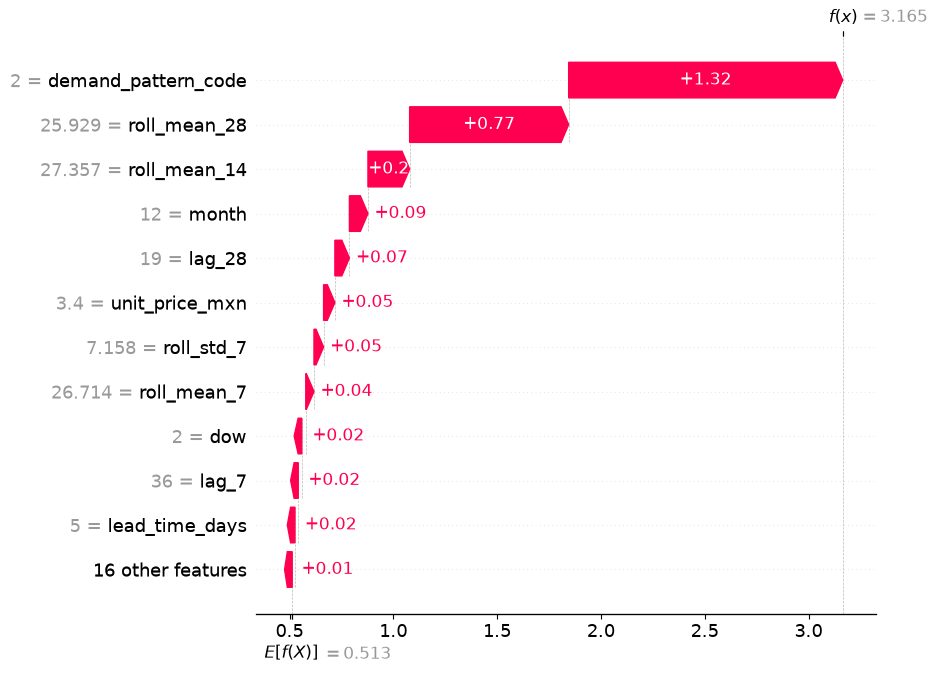

In [8]:
if SHAP_AVAILABLE:
    if plots_available():
        shap.plots.waterfall(latest_explanation, max_display=12, show=False)
        plt.show()
    else:
        display(latest_contributions.head(12).round(4))
else:
    print("SHAP unavailable: waterfall skipped; use the fallback gain importance below.")

### How to read the SHAP bar plot

The bar plot aggregates the absolute SHAP values across all holdout days for this
series. It answers *which features matter most for this product over the forecast
window*, without direction: a feature that pushes up on some days and down on others
still gets a large bar. Use it together with the waterfall: the bar plot ranks the
drivers, the waterfall signs them for a specific day.

,feature,mean_abs_shap
26,demand_pattern_code,1.2924
6,roll_mean_28,0.7470
5,roll_mean_14,0.2000
9,dow,0.0896
17,unit_price_mxn,0.0718
10,month,0.0660
7,roll_std_7,0.0553
3,lag_28,0.0511
4,roll_mean_7,0.0384
21,stock_to_demand,0.0306


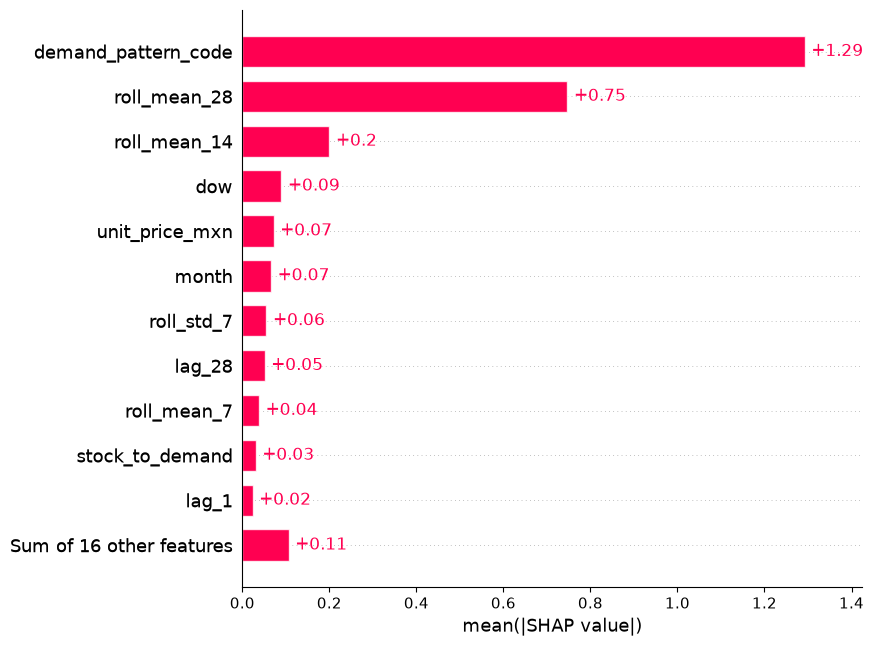

In [9]:
if SHAP_AVAILABLE:
    mean_abs = pd.DataFrame(
        {
            "feature": features,
            "mean_abs_shap": np.abs(np.asarray(shap_values.values, dtype=float)).mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    display(mean_abs.head(12).round(4))
    if plots_available():
        shap.plots.bar(shap_values, max_display=12, show=False)
        plt.show()
    else:
        print("matplotlib unavailable: the ranking table above replaces the bar plot.")
else:
    print("SHAP unavailable: bar plot skipped; use the fallback gain importance below.")

## 4. Limitations: correlated lag features

SHAP attributes the model output, not the data-generating process. Demand features are
strongly correlated by construction, which limits how far a SHAP ranking can be read:

- `lag_1`, `lag_7`, `lag_14`, `lag_28` and `roll_mean_*` are all summaries of the same
  recent-demand history. Across the panel their correlations are high (≈0.6–0.99);
  within a series the raw lags are less correlated, but the rolling means still overlap
  heavily (≈0.78–0.82). When two features carry overlapping information, SHAP can
  assign the credit to either one; adding or removing a near-duplicate can move a large
  bar to another feature without changing the forecast. The ranking is not a statement
  that "lag_28 causes demand".
- With the tree-path-dependent explainer, contributions can be evaluated on feature
  combinations that rarely or never occur (off-manifold rows), which is exactly the risk
  with lag/rolling blocks.
- The categorical codes (`product_code`, `demand_pattern_code`, ...) are arbitrary
  integers. A SHAP value for `demand_pattern_code` means "the model moved the forecast
  because this row falls in the smooth/intermittent/lumpy branch", not "one more unit of
  demand pattern"; do not read it as a numeric slope.
- SHAP is **not causal**. A promotion may lower the forecast because it is correlated
  with a soft month; the explanation cannot separate the discount effect from the
  season. Use it to audit model behaviour, not to design a pricing policy.

The next cell quantifies the collinearity. The full-panel correlations are inflated by
between-series scale differences; the within-series version is the fairer view of
day-to-day redundancy, and even there the rolling means are almost interchangeable.

In [10]:
lag_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "roll_mean_7",
    "roll_mean_14",
    "roll_mean_28",
    "roll_std_7",
]
panel_correlation = train_df[lag_features].corr()
within = train_df[lag_features] - train_df.groupby(
    ["business_id", "branch_id", "product_id"]
)[lag_features].transform("mean")
within_correlation = within.corr()

print("Full-panel correlation (inflated by series scale):")
display(panel_correlation.round(2))
print("Within-series correlation (removes series-level means):")
display(within_correlation.round(2))

Full-panel correlation (inflated by series scale):


,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_14,roll_mean_28,roll_std_7
lag_1,1.00,0.63,0.63,0.63,0.82,0.81,0.80,0.62
lag_7,0.63,1.00,0.67,0.66,0.82,0.81,0.80,0.62
lag_14,0.63,0.67,1.00,0.67,0.76,0.81,0.80,0.55
lag_28,0.63,0.66,0.67,1.00,0.76,0.77,0.80,0.55
roll_mean_7,0.82,0.82,0.76,0.76,1.00,0.98,0.97,0.75
roll_mean_14,0.81,0.81,0.81,0.77,0.98,1.00,0.99,0.72
roll_mean_28,0.80,0.80,0.80,0.80,0.97,0.99,1.00,0.71
roll_std_7,0.62,0.62,0.55,0.55,0.75,0.72,0.71,1.00


Within-series correlation (removes series-level means):


,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_14,roll_mean_28,roll_std_7
lag_1,1.00,0.05,0.04,0.03,0.40,0.31,0.25,0.21
lag_7,0.05,1.00,0.14,0.13,0.40,0.32,0.26,0.21
lag_14,0.04,0.14,1.00,0.13,0.09,0.31,0.27,0.03
lag_28,0.03,0.13,0.13,1.00,0.07,0.09,0.25,0.03
roll_mean_7,0.40,0.40,0.09,0.07,1.00,0.78,0.63,0.52
roll_mean_14,0.31,0.32,0.31,0.09,0.78,1.00,0.82,0.38
roll_mean_28,0.25,0.26,0.27,0.25,0.63,0.82,1.00,0.30
roll_std_7,0.21,0.21,0.03,0.03,0.52,0.38,0.30,1.00


## 5. More limitations and how to use SHAP responsibly

- **Quantile-specific.** This notebook explains the p50. The p10 and p90 are separately
  fitted models and can rely on different features. Safety-stock decisions use the
  interval, so when validating a buffer, explain the p90 model too; do not assume the
  p50 ranking transfers.
- **Global baseline.** The expected value is a panel-level average; a positive
  contribution means "above the panel baseline", not "above this product's average".
  Compare the explained output with the product's own history before drawing business
  conclusions.
- **Single holdout sample.** The bar plot averages the holdout window (28 days in the
  committed run) from one December window.
  It is a diagnostic sample, not a population estimate; a second window can reorder
  features.
- **Preprocessing matters.** The explanation is for the encoded matrix: imputed zeros,
  clipped `stock_to_demand`, `days_since_last_sale=60` for no recent sale. SHAP values
  reflect the model's treatment of those engineered values, not the raw business event.
- **Explainability is offline.** The forecast path returns p10/p50/p90 only; SHAP is an
  audit tool, not part of the request flow. It should never become a runtime dependency
  of forecasting.

## 6. Fallback when SHAP is unavailable

If the guarded import above reported that `shap` is missing, the cell below prints the
install hint and uses the model's native normalized **gain** importance. Gain answers a
different question — how much a feature reduced loss during training, over the whole
ensemble — and has no direction or per-row resolution, but it preserves the feature
ranking and keeps the notebook useful offline.

In [11]:
if SHAP_AVAILABLE:
    print("SHAP is available: the waterfall and bar plots above are the primary explanation.")
else:
    print(SHAP_HINT)
    fallback_importance = pd.DataFrame(
        {
            "feature": features,
            "gain": np.asarray(p50.feature_importances_, dtype=float),
        }
    ).sort_values("gain", ascending=False)
    fallback_importance["gain_share"] = (
        fallback_importance["gain"] / fallback_importance["gain"].sum()
    )
    display(fallback_importance.head(12).round(6))
    if plots_available():
        top = fallback_importance.head(12).iloc[::-1]
        figure, ax = plt.subplots(figsize=(8.5, 5))
        ax.barh(top["feature"], top["gain_share"], color=COLOR_MAIN)
        ax.set_xlabel("normalized gain share (p50 model)")
        ax.set_title("Fallback: native XGBoost gain importance (no SHAP)")
        figure.tight_layout()
        plt.show()
    print(
        "Fallback reading: features are ordered by training loss reduction; the plot "
        "cannot show whether a feature pushes a specific forecast up or down."
    )

SHAP is available: the waterfall and bar plots above are the primary explanation.


## 7. Checklist for explaining a product forecast

1. Confirm model version, training timestamp and dataset SHA-256 from the registry.
2. Confirm the feature contract and encoders match the artifact (this notebook raises
   if they do not).
3. Rebuild features on the full panel; never re-fit encoders on a subset.
4. Compare the base value with the product's recent history: a low base means the
   model starts from the panel average and relies on features to lift the series.
5. Read the top positive/negative waterfall bars, convert log1p contributions with
   `expm1`, and check whether the driver family is dynamic demand or a static prior.
6. Cross-check the explanation with the actual and the holdout error; a plausible
   explanation of a bad forecast is still a bad forecast.
7. For safety stock, explain the p90 model and the `(p90 − p10) / 2.562` interval, not
   just the p50.

**Related notebooks:** `01_eda.ipynb` for the demand patterns that make these
explanations hard, `02_modeling.ipynb` for the champion-vs-baseline evidence and the
refresh triggers.